<a href="https://colab.research.google.com/github/AlexBecerril/miaad-sem1/blob/main/Actividad_Calificada_Particion_Remuestreo_Arbol_275333.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad Calificada: Partición y Remuestreo con Árbol de Decisión

**Programación para Analítica Descriptiva y Predictiva — MIAAD, UACJ**


**Nombre:Edgar** Alejandro Becerril Caballero

**Matricula:** 275333

**Ficha técnica**

| | |
|---|---|
| **Modalidad** | Individual |
| **Entorno** | Google Colab |
| **Dataset** | Titanic (pasajeros del RMS Titanic, clasificación binaria) |
| **Modelo** | Árbol de Decisión (`DecisionTreeClassifier`) |
| **Puntaje total** | 100 puntos |
| **Fecha de entrega** | 22/10/2026 |

**Objetivo**

Aplicar partición hold-out estratificada y dos esquemas de validación cruzada (`StratifiedKFold` y `RepeatedStratifiedKFold`) para estimar el desempeño de un Árbol de Decisión, y justificar, con base en el sesgo y la varianza de la estimación, qué método reportarías como resultado final.

**Dataset**

El dataset contiene 891 pasajeros del Titanic, con la variable `survived` (0 = no sobrevivió, 1 = sobrevivió) como variable objetivo. Tiene valores ausentes genuinos en `age` (177 casos) y `embarked` (2 casos) — no son valores agregados artificialmente para esta actividad.

**Instrucciones generales**

- Completa únicamente las celdas marcadas con `# TODO`. No modifiques las celdas de preparación de datos ni los hiperparámetros ya indicados (`max_depth=4`, `random_state=0`), para que tus resultados sean comparables con los de tus compañeros.
- Cada actividad tiene una parte de código y una pregunta de interpretación en una celda de texto (Markdown). Responde directamente debajo de **Tu respuesta:**.
- No se califican fragmentos de código comentados o dejados sin completar (`# TODO` sin resolver).
- Antes de entregar, ejecuta todo el notebook de principio a fin (`Entorno de ejecución > Reiniciar y ejecutar todo` en Colab) y verifica que no queden errores.

**Entrega**

Sube a Moodle un archivo `.txt` con el enlace a tu notebook de Colab o GitHub (con permisos de lectura habilitados). La subida del archivo `.ipynb` es opcional, pero recomendada como respaldo.


## Preparación de los datos

Esta sección se proporciona completa: no es parte de la evaluación. Carga el dataset, selecciona las variables predictoras y aplica un tratamiento mínimo a los valores ausentes y a las variables categóricas, para que puedas concentrarte en la partición y el remuestreo.


In [35]:
import numpy as np
import pandas as pd
import graphviz

from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_validate, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn.metrics import accuracy_score

np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.precision", 3)

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df = pd.read_csv(url)

print(f"Observaciones: {df.shape[0]}, columnas: {df.shape[1]}")
print("Valores ausentes por columna (solo las que tienen alguno):")
print(df.isna().sum()[df.isna().sum() > 0])

# Variables predictoras: se dejan fuera las que son redundantes con 'survived'
# (alive, who, adult_male), las de muy alta cardinalidad (deck, con 688 ausentes)
# o duplicadas en otra forma (class es la versión en texto de pclass).
variables = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X = df[variables].copy()
y = df["survived"].copy()

# Tratamiento mínimo, dado: imputar age con la mediana y embarked con la moda,
# y codificar las dos variables categóricas como enteros.
X["age"] = X["age"].fillna(X["age"].median())
X["embarked"] = X["embarked"].fillna(X["embarked"].mode()[0])
X["sex"] = X["sex"].map({"male": 0, "female": 1})
X["embarked"] = X["embarked"].map({"S": 0, "C": 1, "Q": 2})

print(f"\nVariables predictoras: {list(X.columns)}")
print(f"Distribución de la variable objetivo (survived): {dict(y.value_counts().sort_index())}")


Observaciones: 891, columnas: 15
Valores ausentes por columna (solo las que tienen alguno):
age            177
embarked         2
deck           688
embark_town      2
dtype: int64

Variables predictoras: ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
Distribución de la variable objetivo (survived): {0: np.int64(549), 1: np.int64(342)}


---
## Actividad 1 — Hold-out estratificado (20 pts)

**1.1 (15 pts).** Completa la partición hold-out: reserva el 20% de las observaciones para prueba, con estratificación por `y` y `random_state=42`. Ajusta un `DecisionTreeClassifier` con `max_depth=4` y `random_state=0` usando el conjunto de entrenamiento, y calcula su accuracy sobre el conjunto de prueba.


In [3]:
# Se realiza una divición hold-out del conjunto de datos,
# conservando el 80% para entrenamiento y el 20% para prueba
# con un random_state 42 para reproducibilidad
# y estratificado en y para asegurar la proporcionalidad de las observaciones
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Se define, entrena y prueba un arbol de decisión
arbol = DecisionTreeClassifier(max_depth=4, random_state=0)
arbol.fit(X_train, y_train)
y_pred = arbol.predict(X_test)

# Se obtiene la certeza del modelo comparando las predicciones con las etiquetas reales
acc_holdout = accuracy_score(y_test, y_pred)

# Se imprimen el número de observaciones de entrenamiento, el número de observaciones
# de prueba y el accuracy obtenido en prueba.
print("Número de observaciones de entrenamiento:", X_train.shape[0])
print("Número de observaciones de prueba:", X_test.shape[0])
print("Accuracy en prueba:", acc_holdout)


Número de observaciones de entrenamiento: 712
Número de observaciones de prueba: 179
Accuracy en prueba: 0.7877094972067039


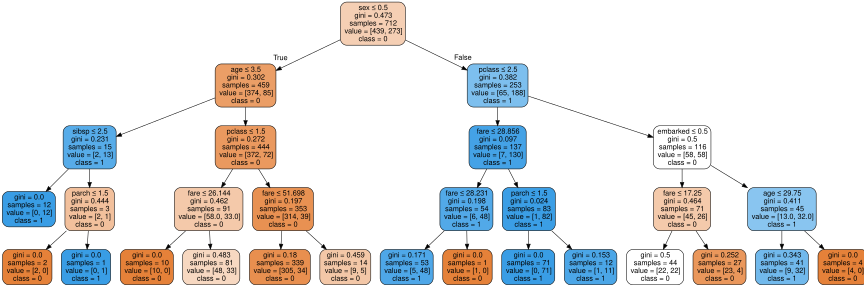

In [22]:
# Se exporta el árbol de decisión a formato DOT
dot_data = export_graphviz(
    arbol,
    out_file=None,
    feature_names=X_train.columns,
    class_names=arbol.classes_.astype(str),
    filled=True,
    rounded=True,
    special_characters=True
)

dot_data = 'digraph { graph [size="12,8", ratio="compress"];' + dot_data.split("{", 1)[1]

# Se genera y muestra el árbol de decisión
graph = graphviz.Source(dot_data)
display(graph)

**1.2 (5 pts).** El Titanic tiene una proporción de supervivencia desbalanceada (aproximadamente 38% sobrevivió, 62% no). ¿Qué problema evita la estratificación (`stratify=y`) en este caso específico, y qué podría pasar con la partición si no se usara?

**Tu respuesta:** Si se realizara una división aleatoria del conjunto de datos, podría pasar que las observaciones de la clase minoritaria quedaran desproporcionadamente distribuidas entre los conjuntos de entrenamiento y prueba. Por ejemplo, podrían quedar menos observaciones de supervivientes en el conjunto de entrenamiento de las que les corresponderían según la proporción original. En ese caso, el modelo tendría menos ejemplos de esa clase para aprender sus patrones, lo que podría afectar su capacidad para generalizar y predecir correctamente la supervivencia.

Para evitar esto, utilizamos la estratificación mediante `stratify=y`, indicando cuál es la columna que contiene las etiquetas. De esta manera, al dividir el conjunto de datos, se conserva aproximadamente la proporción original de cada clase tanto en el conjunto de entrenamiento como en el de prueba, permitiendo que ambos conjuntos sean más representativos de la distribución original.


---
## Actividad 2 — StratifiedKFold (25 pts)

**2.1 (15 pts).** Completa la validación cruzada con `StratifiedKFold`: 5 folds, `shuffle=True` y `random_state=42`. Usa `cross_validate` con un `DecisionTreeClassifier(max_depth=4, random_state=0)` nuevo (mismos hiperparámetros que en la Actividad 1) y reporta la media y la desviación estándar (`ddof=1`) del accuracy sobre los 5 folds.


In [30]:
# Se define la estrategia de validación cruzada estratificada con StratifiedKFold,
# dividiendo el conjunto de datos en 5 folds, mezclando las observaciones antes
# de realizar la división (shuffle=True) y utilizando un random_state de 42
# para asegurar la reproducibilidad de las particiones.
cv_kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Se define un árbol de decisión con una profundidad máxima de 4 niveles
# y un random_state de 0 para mantener la reproducibilidad del modelo.
# Posteriormente, se realiza la validación cruzada utilizando accuracy como
# métrica de evaluación y se guardan los modelos entrenados en cada fold.
arbol_kfold = DecisionTreeClassifier(max_depth=4, random_state=0)
resultados_kfold = cross_validate(arbol_kfold, X, y, cv=cv_kfold, scoring='accuracy',return_estimator=True)

scores_kfold = resultados_kfold['test_score']

# Se imprime el accuracy obtenido en cada fold, la media de los resultados
# para conocer el desempeño promedio del modelo y la desviación estándar
# muestral (ddof=1) para medir la variabilidad del accuracy entre los folds.
print("Accuracy en cada fold:", scores_kfold)
print("Media del accuracy:", np.mean(scores_kfold))
print("Desviación estándar del accuracy:", np.std(scores_kfold, ddof=1))


Accuracy en cada fold: [0.832 0.826 0.792 0.809 0.837]
Media del accuracy: 0.8192894356914193
Desviación estándar del accuracy: 0.018539304855359564


**2.2 (10 pts).** Compara la media del accuracy de `StratifiedKFold` con el accuracy único que obtuviste en la Actividad 1. ¿Por qué un solo valor de hold-out no es suficiente para saber si ese resultado es representativo del desempeño real del modelo?

**Tu respuesta:** El accuracy obtenido con el método hold-out fue de aproximadamente 78.77%, mientras que con la validación cruzada utilizando StratifiedKFold se obtuvo una media de aproximadamente 81.93%, con una desviación estándar de 1.85 puntos porcentuales entre los cinco folds.

La diferencia entre ambos resultados muestra que el desempeño del modelo puede variar dependiendo de cómo se dividan los datos de entrenamiento y prueba. Un solo valor de hold-out no es suficiente para determinar si el resultado es representativo del desempeño real del modelo, ya que depende de una única partición de los datos. Si la distribución de las observaciones en esa partición no resulta favorable, el accuracy podría ser menor; si resulta más favorable, podría ser mayor.

En cambio, la validación cruzada permite evaluar el modelo en diferentes particiones, obteniendo una medida del desempeño promedio y de su variabilidad. En este caso, la desviación estándar relativamente baja indica que los valores de accuracy fueron bastante consistentes entre los cinco folds, lo que aporta mayor confianza en la estimación del desempeño del modelo.


---
## Actividad 3 — RepeatedStratifiedKFold (25 pts)

**3.1 (15 pts).** Completa la validación cruzada repetida: 5 folds, 5 repeticiones y `random_state=42`. Usa `cross_validate` con el mismo modelo (`DecisionTreeClassifier(max_depth=4, random_state=0)`) y reporta la media y la desviación estándar (`ddof=1`) sobre las 25 estimaciones resultantes.


In [33]:
# Se define la estrategia de validación cruzada estratificada repetida,
# dividiendo el conjunto de datos en 5 folds y repitiendo el proceso 5 veces.
# Se utiliza un random_state de 42 para asegurar la reproducibilidad
# de las particiones.
cv_repetido = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

# Se define un árbol de decisión con una profundidad máxima de 4 niveles
# y un random_state de 0 para mantener la reproducibilidad del modelo.
# Posteriormente, se realiza la validación cruzada utilizando accuracy
# como métrica de evaluación y se guardan los modelos entrenados en cada fold.
arbol_repetido = DecisionTreeClassifier(max_depth=4, random_state=0)
resultados_repetido = cross_validate(arbol_repetido, X, y, cv=cv_repetido, scoring='accuracy', return_estimator=True)

# Se extraen los valores de accuracy obtenidos en los conjuntos de prueba
# de cada una de las particiones realizadas durante la validación cruzada.
scores_repetido = resultados_repetido['test_score']

# Se imprime el número total de estimaciones obtenidas, la media del accuracy
# para conocer el desempeño promedio del modelo y la desviación estándar
# muestral (ddof=1) para medir la variabilidad de los resultados.
print("Accuracy en cada fold:", scores_repetido)
print("Número de estimaciones:", len(scores_repetido))
print("Media del accuracy:", np.mean(scores_repetido))
print("Desviación estándar del accuracy:", np.std(scores_repetido, ddof=1))


Accuracy en cada fold: [0.832 0.826 0.792 0.809 0.837 0.765 0.82  0.792 0.775 0.809 0.838 0.82
 0.843 0.809 0.792 0.821 0.775 0.82  0.781 0.809 0.799 0.792 0.837 0.82
 0.803]
Número de estimaciones: 25
Media del accuracy: 0.8087514908040926
Desviación estándar del accuracy: 0.021675206542394264


**3.2 (10 pts).** Compara la desviación estándar de `RepeatedStratifiedKFold` con la de `StratifiedKFold` (Actividad 2). ¿Qué fuente de variabilidad adicional captura la versión repetida que una sola corrida de `StratifiedKFold` no puede capturar?

**Tu respuesta:**


---
## Actividad 4 — Comparación y justificación (15 pts)

**4.1 (10 pts).** Completa la tabla comparativa con los tres resultados obtenidos. Para hold-out, al ser una sola estimación, no hay desviación estándar.


In [11]:
# TODO 4.1: completa la tabla comparativa con los tres métodos.
resumen = pd.DataFrame({
    "método": ["Hold-out", "StratifiedKFold", "RepeatedStratifiedKFold"],
    "n_estimaciones": [1, 5, 25],  # completa: número de estimaciones de cada método
    "media_accuracy": [0.79, 0.82, 0.81],  # completa con los tres valores ya calculados
    "desv_est": [np.nan, 0.0185, 0.0216],  # completa; np.nan para hold-out
})
resumen


,método,n_estimaciones,media_accuracy,desv_est
0,Hold-out,1,0.79,NaN
1,StratifiedKFold,5,0.82,0.018
2,RepeatedStratifiedKFold,25,0.81,0.022


**4.2 (5 pts).** Si tuvieras que reportar un solo número como el desempeño esperado de este Árbol de Decisión en el dataset del Titanic, ¿cuál de los tres métodos usarías y por qué? Justifica tu respuesta en términos de sesgo y varianza de la estimación, no solo del valor de accuracy obtenido.

**Tu respuesta:** Utilizaría la media del accuracy obtenida con `RepeatedStratifiedKFold`, que fue de aproximadamente 81%, porque considero que permite obtener una estimación del desempeño esperado menos dependiente de una única división de los datos.

En comparación, el método hold-out obtuvo un accuracy de 79%, pero este resultado depende de una sola partición, por lo que podría variar si se realizara una división diferente.

En términos de sesgo y varianza, elegiría `RepeatedStratifiedKFold` porque ofrece una evaluación más amplia de la sensibilidad del modelo a las particiones, aunque esto no garantiza que su estimación tenga menor sesgo. Por lo tanto, considero que el accuracy medio de 81% es una referencia razonable del desempeño esperado del modelo.

---
## Reflexión final (15 pts)

Responde en 6 a 10 líneas: ¿qué papel juega la elección del método de partición o remuestreo cuando se evalúa un modelo de clasificación, y qué factores del problema (tamaño del dataset, balance de clases, costo de entrenamiento) tomarías en cuenta para elegir uno sobre otro en un caso distinto al de esta actividad?

**Tu respuesta:** La elección del método de partición o remuestreo es importante porque influye en la forma en que evaluamos el desempeño de un modelo y en qué tan representativos son los resultados obtenidos. Un método inadecuado podría generar una evaluación poco confiable, dependiendo de cómo se distribuyan las observaciones entre los conjuntos de entrenamiento y prueba.

Para elegir un método, tomaría en cuenta el tamaño del conjunto de datos, ya que con pocos datos sería conveniente utilizar validación cruzada para aprovechar mejor las observaciones disponibles. También consideraría el balance de las clases, utilizando estratificación cuando exista una clase minoritaria para conservar aproximadamente su proporción en cada partición. Por otro lado, tomaría en cuenta el costo computacional, porque los métodos repetidos requieren entrenar el modelo más veces y, por lo tanto, consumen más tiempo y recursos. Finalmente, elegiría el método que permita obtener una evaluación suficientemente confiable sin generar un costo computacional innecesario.


## Extra

Únicamente con fines ilustrativos y aunque resulte computacionalmente costoso, quise probar diferentes combinaciones de hiperparámetros para identificar si es posible encontrar una configuración que permita obtener un mejor desempeño del modelo. Para ello, utilicé `GridSearchCV`, evaluando diferentes valores de `max_depth` y distintas configuraciones de validación cruzada mediante `n_splits` y `n_repeats`. El objetivo fue comparar los resultados obtenidos y observar cómo cambia el accuracy según la configuración utilizada.

In [37]:
# Hiperparámetros del árbol
param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10, None]
}

# Configuraciones de validación cruzada
configuraciones_cv = [
    {'n_splits': 5, 'n_repeats': 2},
    {'n_splits': 5, 'n_repeats': 5},
    {'n_splits': 10, 'n_repeats': 2},
    {'n_splits': 10, 'n_repeats': 5}
]

In [38]:
resultados = []

for config in configuraciones_cv:

    cv = RepeatedStratifiedKFold(
        n_splits=config['n_splits'],
        n_repeats=config['n_repeats'],
        random_state=42
    )

    modelo = DecisionTreeClassifier(random_state=0)

    grid = GridSearchCV(
        estimator=modelo,
        param_grid=param_grid,
        scoring='accuracy',
        cv=cv,
        n_jobs=-1,
        return_train_score=True
    )

    grid.fit(X, y)

    resultados.append({
        'n_splits': config['n_splits'],
        'n_repeats': config['n_repeats'],
        'max_depth': grid.best_params_['max_depth'],
        'accuracy_media': grid.best_score_,
        'desviacion_estandar': grid.cv_results_['std_test_score'][
            grid.best_index_
        ]
    })

resultados_df = pd.DataFrame(resultados)

resultados_df = resultados_df.sort_values(
    by='accuracy_media',
    ascending=False
)

resultados_df

,n_splits,n_repeats,max_depth,accuracy_media,desviacion_estandar
2,10,2,3,0.818,0.028
0,5,2,8,0.817,0.028
1,5,5,8,0.816,0.022
3,10,5,3,0.815,0.033


**Reflexión:** Los resultados obtenidos muestran que la mejor combinación evaluada fue la de 5 folds, 10 repeticiones y una profundidad máxima de 2, con un accuracy medio de 81.8% y una desviación estándar de 2.8%. Sin embargo, las diferencias entre las combinaciones son pequeñas, ya que todas obtuvieron un accuracy medio entre 81.5% y 81.8%. Esto sugiere que aumentar la complejidad del árbol no necesariamente mejora su desempeño.

---
## Rúbrica

| Criterio | Excelente | Bueno | Insuficiente | No entregado / Incorrecto | Puntos |
|---|---|---|---|---|---|
| **1.1 Hold-out estratificado** | Partición y ajuste correctos; accuracy calculado e interpretado correctamente. | Partición y ajuste correctos, con un error menor (p. ej. un argumento incompleto) que no afecta el resultado final. | Partición o ajuste con errores que alteran el resultado (p. ej. sin estratificar, sin `random_state`). | Celda sin completar o con errores que impiden su ejecución. | 15 |
| **1.2 Interpretación de la estratificación** | Explica correctamente el riesgo de desbalance en la partición y por qué `stratify` lo evita. | Explica la idea general pero de forma incompleta o imprecisa. | Respuesta genérica, sin relación con el desbalance de clases del dataset. | Sin respuesta. | 5 |
| **2.1 StratifiedKFold** | Configuración correcta de `cv` y `cross_validate`; media y desviación estándar reportadas con `ddof=1`. | Correcto, con un error menor que no cambia el resultado (p. ej. `ddof` por defecto). | Configuración incompleta o métrica mal calculada. | Celda sin completar o con errores que impiden su ejecución. | 15 |
| **2.2 Comparación hold-out vs. k-fold** | Explica con claridad por qué una sola partición no es representativa y cómo k-fold promedia sobre varias particiones. | Identifica la idea central pero sin justificarla completamente. | Comparación superficial, sin referirse a la variabilidad entre particiones. | Sin respuesta. | 10 |
| **3.1 RepeatedStratifiedKFold** | Configuración correcta de `cv` y `cross_validate`; media y desviación estándar reportadas sobre las 25 estimaciones. | Correcto, con un error menor que no cambia el resultado. | Configuración incompleta (p. ej. `n_repeats` incorrecto) o métrica mal calculada. | Celda sin completar o con errores que impiden su ejecución. | 15 |
| **3.2 Fuente de variabilidad adicional** | Identifica correctamente que la repetición varía la configuración de folds entre repeticiones, no solo las observaciones dentro de un fold. | Identifica que hay más variabilidad capturada, sin precisar el mecanismo. | Respuesta genérica o incorrecta sobre qué varía entre repeticiones. | Sin respuesta. | 10 |
| **4.1 Tabla comparativa** | Tabla completa y correcta, con `np.nan` o vacío en la desviación estándar de hold-out. | Tabla completa con un valor incorrecto o mal ubicado. | Tabla incompleta o con varios valores incorrectos. | Celda sin completar. | 10 |
| **4.2 Justificación del método elegido** | Justifica la elección con el argumento de sesgo/varianza de la estimación, no solo con el valor numérico de accuracy. | Justifica la elección, pero basándose solo en qué método dio el accuracy más alto. | Elige un método sin justificación relacionada con sesgo o varianza. | Sin respuesta. | 5 |
| **Reflexión final** | Identifica con claridad los factores relevantes (tamaño del dataset, balance de clases, costo) y los conecta con el método de partición o remuestreo adecuado. | Identifica algunos factores relevantes, de forma parcial. | Reflexión genérica, sin relación específica con los factores de decisión vistos en la sesión. | Sin respuesta. | 15 |

**Nota.** La penalización por entrega tardía es del 5% por día calendario, hasta 7 días, después de lo cual la actividad recibe 0 puntos. Esta penalización se aplica sobre el puntaje ya obtenido con la rúbrica, no como parte de ella.
